# E-Commerce Customer & Product Analysis

## Exploratory Data Analysis

This notebook explores e-commerce sales, customer behavior, product performance, and profitability to identify trends and business opportunities.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
sales = pd.read_csv("../01_data/raw/ecommerce_sales_customer_analytics.csv")
order_items = pd.read_csv("../01_data/raw/order_items.csv")
products = pd.read_csv("../01_data/raw/product_catalog.csv")

## Data Quality & Validation

## 1. Data Overview

This analysis uses three related datasets containing e-commerce sales, customer, order-item, and product information.

### Datasets

- **Sales & Customer Analytics:** Order-level sales and customer information
- **Order Items:** Product-level details for each order
- **Product Catalog:** Product attributes, pricing, brands, and categories

In [4]:
# Columns and Dimensions

print("Sales & Customer Analytics")
print(f"Rows: {sales.shape[0]:,}")
print(f"Columns: {sales.shape[1]}")

print("\nOrder Items")
print(f"Rows: {order_items.shape[0]:,}")
print(f"Columns: {order_items.shape[1]}")

print("\nProduct Catalog")
print(f"Rows: {products.shape[0]:,}")
print(f"Columns: {products.shape[1]}")

Sales & Customer Analytics
Rows: 138,116
Columns: 46

Order Items
Rows: 397,569
Columns: 12

Product Catalog
Rows: 1,175
Columns: 9


In [5]:
# Data Types

sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

In [6]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 397569 entries, 0 to 397568
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             397569 non-null  str    
 1   product_id           397569 non-null  str    
 2   quantity             397569 non-null  int64  
 3   unit_price           397569 non-null  float64
 4   discount_percentage  397569 non-null  float64
 5   discount_amount      397569 non-null  float64
 6   gross_sales          397569 non-null  float64
 7   tax_amount           397569 non-null  float64
 8   shipping_cost        397569 non-null  float64
 9   net_sales            397569 non-null  float64
 10  product_cost         397569 non-null  float64
 11  profit               397569 non-null  float64
dtypes: float64(9), int64(1), str(2)
memory usage: 36.4 MB


In [7]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 1175 entries, 0 to 1174
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1175 non-null   str    
 1   product_name         1175 non-null   str    
 2   product_category     1175 non-null   str    
 3   product_subcategory  1175 non-null   str    
 4   brand                1175 non-null   str    
 5   supplier             1175 non-null   str    
 6   unit_price           1175 non-null   float64
 7   product_cost         1175 non-null   float64
 8   product_rating       1175 non-null   float64
dtypes: float64(3), str(6)
memory usage: 82.7 KB


In [8]:
# Date Range

sales["order_date"] = pd.to_datetime(sales["order_date"])

print("Earliest order:", sales["order_date"].min())
print("Latest order:", sales["order_date"].max())

/var/folders/md/tzw8094d2gg6wckgnvbcvmlc0000gn/T/ipykernel_58466/1068749286.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sales["order_date"] = pd.to_datetime(sales["order_date"])


Earliest order: 2021-01-01 00:00:00
Latest order: 2025-12-31 00:00:00


In [9]:
sales["order_date"].describe()

count                        138116
mean     2023-07-21 10:11:31.662081
min             2021-01-01 00:00:00
25%             2022-04-20 00:00:00
50%             2023-08-01 00:00:00
75%             2024-10-29 00:00:00
max             2025-12-31 00:00:00
Name: order_date, dtype: object


### Initial Data Overview Findings

- The sales dataset contains 138,116 order records and 46 columns.
- The order-items dataset contains 397,569 records across 12 columns.
- The product catalog contains 1,175 products and 9 columns.
- The datasets cover orders from January 2021 through December 2025.
- No exact duplicate rows were identified in the three datasets.
- Each order ID appears once in the sales dataset, while the order-items dataset contains multiple product records per order.

The initial inspection also identified missing values in return information, coupon usage, marketing campaigns, customer reviews, and delivery-related fields. These will be investigated to determine whether the missing values are expected or require attention.


### 2. Missing Values

In [10]:
print("Sales missing values:")
display(sales.isnull().sum().sort_values(ascending=False))

print("\nOrder Items missing values:")
display(order_items.isnull().sum().sort_values(ascending=False))

print("\nProducts missing values:")
display(products.isnull().sum().sort_values(ascending=False))

Sales missing values:


return_reason               128654
return_status               128654
coupon_code                 110502
campaign_name                83233
customer_review              24557
customer_rating              24557
estimated_delivery_days      24557
delivery_days                24557
review_sentiment             24557
order_id                         0
order_time                       0
order_status                     0
sales_channel                    0
order_date                       0
customer_country                 0
customer_state                   0
customer_city                    0
customer_type                    0
customer_segment                 0
gender                           0
customer_age                     0
customer_name                    0
customer_id                      0
shipping_method                  0
warehouse                        0
payment_status                   0
customer_postal_code             0
payment_method                   0
currency            


Order Items missing values:


order_id               0
product_id             0
quantity               0
unit_price             0
discount_percentage    0
discount_amount        0
gross_sales            0
tax_amount             0
shipping_cost          0
net_sales              0
product_cost           0
profit                 0
dtype: int64


Products missing values:


product_id             0
product_name           0
product_category       0
product_subcategory    0
brand                  0
supplier               0
unit_price             0
product_cost           0
product_rating         0
dtype: int64

In [11]:

# Check return statuses
print("Return status counts:")
display(sales["return_status"].value_counts(dropna=False))

# Check coupon usage
print("\nCoupon code counts:")
display(sales["coupon_code"].value_counts(dropna=False).head(10))

# Check delivery and review field missingness
fields_to_check = [
    "delivery_days",
    "estimated_delivery_days",
    "customer_rating",
    "review_sentiment",
    "customer_review",
    "campaign_name",
    "coupon_code"
]

missing_summary = pd.DataFrame({
    "Missing Count": sales[fields_to_check].isnull().sum(),
    "Missing Percentage": (
        sales[fields_to_check].isnull().mean() * 100
    ).round(2)
})

display(missing_summary.sort_values("Missing Percentage", ascending=False))


Return status counts:


return_status
NaN         128654
Returned      9462
Name: count, dtype: int64


Coupon code counts:


coupon_code
NaN       110502
SAVE39       731
SAVE49       727
SAVE40       719
SAVE12       716
SAVE33       715
SAVE26       712
SAVE25       711
SAVE15       709
SAVE36       709
Name: count, dtype: int64

,Missing Count,Missing Percentage
coupon_code,110502,80.01
campaign_name,83233,60.26
delivery_days,24557,17.78
customer_rating,24557,17.78
estimated_delivery_days,24557,17.78
customer_review,24557,17.78
review_sentiment,24557,17.78


In [12]:

# Compare coupon usage with discount amounts

sales["has_coupon"] = sales["coupon_code"].notna()

coupon_analysis = sales.groupby("has_coupon").agg(
    order_count=("order_id", "count"),
    total_discount=("discount_amount", "sum"),
    average_discount=("discount_amount", "mean"),
    zero_discount_orders=(
        "discount_amount",
        lambda x: (x == 0).sum()
    )
)

display(coupon_analysis.round(2))


,order_count,total_discount,average_discount,zero_discount_orders
has_coupon,,,,
False,110502,26307378.53,238.07,14236
True,27614,6511968.29,235.82,3628


In [13]:

# Compare order status with return status

return_analysis = pd.crosstab(
    sales["order_status"],
    sales["return_status"],
    dropna=False
)

display(return_analysis)


return_status,Returned,NaN
order_status,,
Cancelled,0,8398
Completed,0,113559
Pending,0,6697
Returned,9462,0


### 3. Duplicate & ID Validation

In [14]:
# Exact Duplicate Checks

print("Sales duplicate rows:", sales.duplicated().sum())
print("Order item duplicate rows:", order_items.duplicated().sum())
print("Product duplicate rows:", products.duplicated().sum())

Sales duplicate rows: 0
Order item duplicate rows: 0
Product duplicate rows: 0


In [15]:
print("Duplicate order IDs in sales:", sales["order_id"].duplicated().sum())
print("Duplicate product IDs in products:", products["product_id"].duplicated().sum())

Duplicate order IDs in sales: 0
Duplicate product IDs in products: 0


In [16]:
print("Unique orders in sales:", sales["order_id"].nunique())
print("Rows in sales:", len(sales))

print("\nUnique orders in order_items:", order_items["order_id"].nunique())
print("Rows in order_items:", len(order_items))

print("\nUnique products in order_items:", order_items["product_id"].nunique())
print("Products in catalog:", products["product_id"].nunique())

Unique orders in sales: 138116
Rows in sales: 138116

Unique orders in order_items: 138116
Rows in order_items: 397569

Unique products in order_items: 1175
Products in catalog: 1175


In [17]:

# Check order IDs between sales and order items
sales_order_ids = set(sales["order_id"])
item_order_ids = set(order_items["order_id"])

print(
    "Orders in order_items but not sales:",
    len(item_order_ids - sales_order_ids)
)

print(
    "Orders in sales but not order_items:",
    len(sales_order_ids - item_order_ids)
)

# Check product IDs between order items and product catalog
item_product_ids = set(order_items["product_id"])
catalog_product_ids = set(products["product_id"])

print(
    "Products in order_items but not catalog:",
    len(item_product_ids - catalog_product_ids)
)

print(
    "Products in catalog but not order_items:",
    len(catalog_product_ids - item_product_ids)
)


Orders in order_items but not sales: 0
Orders in sales but not order_items: 0
Products in order_items but not catalog: 0
Products in catalog but not order_items: 0


### 4. Value Validity Checks & Financial Data Validation

In [18]:

# Check quantities and financial values

financial_columns = [
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "profit"
]

print("Non-positive quantities:", (sales["quantity"] <= 0).sum())
print("Negative gross sales:", (sales["gross_sales"] < 0).sum())
print("Negative net sales:", (sales["net_sales"] < 0).sum())
print("Negative product costs:", (sales["product_cost"] < 0).sum())

print("\nFinancial summary:")
display(sales[financial_columns].describe().round(2))


Non-positive quantities: 0
Negative gross sales: 0
Negative net sales: 0
Negative product costs: 0

Financial summary:


,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit
count,138116.00,138116.00,138116.00,138116.00,138116.00,138116.00,138116.00
mean,1375.38,237.62,122.46,22.28,1282.50,708.90,551.32
std,1291.01,378.78,140.94,16.02,1169.27,730.04,516.30
min,6.31,0.00,0.34,0.00,5.80,1.97,-1281.59
25%,458.92,26.33,34.65,9.82,448.20,207.67,190.76
50%,995.73,103.28,77.01,19.19,950.76,478.96,408.40
75%,1871.20,277.12,156.20,30.75,1744.58,953.76,752.84
max,16051.19,6759.02,2091.52,149.52,16218.00,9963.41,7083.68


In [19]:

# Check currencies and financial totals

print("Currency values:")
display(sales["currency"].value_counts(dropna=False))

print("\nOrder-level financial totals:")
display(
    sales[
        ["gross_sales", "discount_amount", "tax_amount",
         "shipping_cost", "net_sales", "product_cost", "profit"]
    ].sum().round(2).to_frame("total")
)

# Compare the financial totals in both datasets
financial_columns = [
    "gross_sales", "discount_amount", "tax_amount",
    "shipping_cost", "net_sales", "product_cost", "profit"
]

print("\nFinancial totals by dataset:")
for column in financial_columns:
    if column in sales.columns and column in order_items.columns:
        print(
            f"{column}: "
            f"sales = {sales[column].sum():,.2f} | "
            f"order_items = {order_items[column].sum():,.2f}"
        )


Currency values:


currency
USD    82600
GBP    20235
EUR    11593
CAD     7015
AUD     6794
INR     5707
AED     4172
Name: count, dtype: int64


Order-level financial totals:


,total
gross_sales,1.899626e+08
discount_amount,3.281935e+07
tax_amount,1.691409e+07
shipping_cost,3.076959e+06
net_sales,1.771343e+08
product_cost,9.791091e+07
profit,7.614640e+07



Financial totals by dataset:
gross_sales: sales = 189,962,560.88 | order_items = 206,343,698.09
discount_amount: sales = 32,819,346.82 | order_items = 35,649,166.70
tax_amount: sales = 16,914,090.41 | order_items = 18,361,184.20
shipping_cost: sales = 3,076,959.27 | order_items = 3,343,161.70
net_sales: sales = 177,134,263.74 | order_items = 192,398,877.29
product_cost: sales = 97,910,908.71 | order_items = 106,357,677.04
profit: sales = 76,146,395.76 | order_items = 82,698,038.55


In [20]:

# Compare financial values across currencies

currency_summary = sales.groupby("currency").agg(
    order_count=("order_id", "count"),
    average_gross_sales=("gross_sales", "mean"),
    average_net_sales=("net_sales", "mean"),
    total_gross_sales=("gross_sales", "sum"),
    total_net_sales=("net_sales", "sum"),
    total_profit=("profit", "sum")
).round(2)

display(currency_summary)


,order_count,average_gross_sales,average_net_sales,total_gross_sales,total_net_sales,total_profit
currency,,,,,,
AED,4172,1394.95,1238.25,5.819715e+06,5.165973e+06,2032453.62
AUD,6794,1390.34,1297.28,9.445972e+06,8.813691e+06,3692395.15
CAD,7015,1376.38,1311.31,9.655322e+06,9.198848e+06,4035038.56
EUR,11593,1379.89,1383.95,1.599708e+07,1.604417e+07,7595233.31
GBP,20235,1372.07,1381.92,2.776388e+07,2.796320e+07,13266357.16
INR,5707,1371.95,1352.42,7.829742e+06,7.718287e+06,3601652.06
USD,82600,1373.50,1237.65,1.134508e+08,1.022301e+08,41923265.90


In [21]:

# Compare order-level totals with summed order-item values

financial_columns = [
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "profit"
]

# Sum item-level values for each order
item_totals = order_items.groupby("order_id")[financial_columns].sum()

# Keep the order-level values for comparison
sales_totals = sales.set_index("order_id")[financial_columns]

# Align the two datasets by order ID
comparison = sales_totals.join(
    item_totals,
    how="inner",
    lsuffix="_sales",
    rsuffix="_items"
)

# Calculate the difference for each order and metric
for column in financial_columns:
    comparison[f"{column}_difference"] = (
        comparison[f"{column}_items"] - comparison[f"{column}_sales"]
    )

print("Number of orders compared:", len(comparison))

print("\nAverage and maximum absolute differences by metric:")
for column in financial_columns:
    difference = comparison[f"{column}_difference"]
    print(
        f"{column}: "
        f"average absolute difference = {difference.abs().mean():,.2f}; "
        f"maximum absolute difference = {difference.abs().max():,.2f}"
    )

print("\nExample orders with the largest gross-sales differences:")
display(
    comparison.assign(
        absolute_difference=comparison["gross_sales_difference"].abs()
    )
    .sort_values("absolute_difference", ascending=False)
    [[
        "gross_sales_sales",
        "gross_sales_items",
        "gross_sales_difference",
        "net_sales_sales",
        "net_sales_items",
        "profit_sales",
        "profit_items"
    ]]
    .head(10)
    .round(2)
)


/var/folders/md/tzw8094d2gg6wckgnvbcvmlc0000gn/T/ipykernel_58466/1290437766.py:20: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = sales_totals.join(


Number of orders compared: 138116

Average and maximum absolute differences by metric:
gross_sales: average absolute difference = 118.60; maximum absolute difference = 12,266.97
discount_amount: average absolute difference = 20.49; maximum absolute difference = 5,035.72
tax_amount: average absolute difference = 10.48; maximum absolute difference = 1,661.61
shipping_cost: average absolute difference = 1.93; maximum absolute difference = 157.61
net_sales: average absolute difference = 110.52; maximum absolute difference = 11,139.31
product_cost: average absolute difference = 61.16; maximum absolute difference = 7,781.45
profit: average absolute difference = 47.71; maximum absolute difference = 5,181.37

Example orders with the largest gross-sales differences:


,gross_sales_sales,gross_sales_items,gross_sales_difference,net_sales_sales,net_sales_items,profit_sales,profit_items
order_id,,,,,,,
ORD-692516,3952.32,16219.29,12266.97,1894.21,11764.31,-351.81,2829.94
ORD-484077,123.83,12016.46,11892.63,145.48,7512.44,80.98,-363.58
ORD-473834,2272.89,13753.15,11480.26,2486.67,12418.78,1348.00,4716.15
ORD-722716,219.95,10952.56,10732.61,208.43,10646.84,90.90,4220.08
ORD-301238,2619.85,13125.26,10505.41,2595.70,13495.75,1131.59,6312.96
ORD-182458,364.35,10849.31,10484.96,285.68,11424.99,89.52,4664.52
ORD-938068,987.32,10847.16,9859.84,1062.34,8852.00,477.58,1771.64
ORD-639357,982.32,10658.17,9675.85,664.59,9997.06,162.83,4078.10
ORD-806449,2289.81,11704.99,9415.18,1371.53,7638.32,283.30,1062.49


In [22]:
# Compare average order value across currencies

currency_check = sales.groupby("currency").agg(
    order_count=("order_id", "count"),
    avg_gross_sales=("gross_sales", "mean"),
    median_gross_sales=("gross_sales", "median"),
    avg_net_sales=("net_sales", "mean"),
    median_net_sales=("net_sales", "median")
).round(2)

display(currency_check)

,order_count,avg_gross_sales,median_gross_sales,avg_net_sales,median_net_sales
currency,,,,,
AED,4172,1394.95,1008.42,1238.25,926.69
AUD,6794,1390.34,1006.80,1297.28,961.94
CAD,7015,1376.38,1009.89,1311.31,989.99
EUR,11593,1379.89,997.23,1383.95,1025.10
GBP,20235,1372.07,1005.24,1381.92,1036.38
INR,5707,1371.95,980.47,1352.42,990.54
USD,82600,1373.50,991.79,1237.65,915.62


### Data Quality Findings

- No exact duplicate records were found in the three datasets.
- All orders in the `sales` table are represented in `order_items`, and all products in `order_items` are represented in `product_catalog`.
- The `sales` dataset contains 138,116 unique orders covering January 2021 through December 2025.
- Several fields contain expected missing values, including return information, coupon codes, campaign names, and customer review information.
- Return records are consistent with order status: all orders marked as returned also have a returned status.
- Financial fields contain no negative gross sales, net sales, or product costs, although some orders have negative profit.
- The `sales` and `order_items` financial fields do not reconcile at the order level, indicating that the two datasets use different financial calculations or representations. For this analysis, order-level financial metrics will be sourced from `sales`, while product-level analysis will use `order_items` and `product_catalog`.
- The dataset contains seven currency labels. Average order values are similar across currencies, suggesting that financial values are represented on a standardized scale. Because the dataset does not document the currency conversion methodology, currency conversion will not be performed as part of this analysis.


## Analysis Dataset Preparation

To ensure consistent financial comparisons, the analysis uses completed orders recorded in USD. This avoids aggregating monetary values across currencies without documented exchange rates.

The original dataset is preserved for data quality checks and broader exploration. A filtered dataset (`sales_usd`) is used for financial analysis.

**Scope:** Completed USD orders from January 2021 through December 2025.


In [68]:
# Create a consistent dataset for financial analysis

sales_usd = sales[
    (sales["currency"] == "USD") &
    (sales["order_status"] == "Completed")
].copy()

print("Total orders in original dataset:", len(sales))
print("Completed USD orders:", len(sales_usd))

print("\nDate range:")
print("Earliest order:", sales_usd["order_date"].min())
print("Latest order:", sales_usd["order_date"].max())

print("\nFinancial totals (USD):")
print(
    sales_usd[["net_sales", "profit"]]
    .sum()
    .round(2)
)

Total orders in original dataset: 138116
Completed USD orders: 67978

Date range:
Earliest order: 2021-01-01 00:00:00
Latest order: 2025-12-31 00:00:00

Financial totals (USD):
net_sales    83344126.98
profit       32860657.92
dtype: float64


## Sales Performance Analysis

### Revenue Over Time

To understand overall sales performance, monthly revenue is analyzed from 2021 through 2025. This helps identify growth patterns, seasonal trends, and periods of unusually high or low sales.

In [24]:
# Calculate monthly revenue and order volume
# Completed USD orders only

monthly_sales = (
    sales_usd
    .set_index("order_date")
    .resample("ME")
    .agg(
        revenue=("net_sales", "sum"),
        orders=("order_id", "count"),
        profit=("profit", "sum")
    )
    .reset_index()
)

monthly_sales.head()

,order_date,revenue,orders,profit
0,2021-01-31,1157475.56,966,520317.06
1,2021-02-28,875871.21,763,390282.17
2,2021-03-31,1345617.19,1097,602384.71
3,2021-04-30,1186742.57,980,532847.75
4,2021-05-31,1144793.27,1023,516173.03


In [25]:
display(monthly_sales.tail())

,order_date,revenue,orders,profit
55,2025-08-31,1441773.01,1184,645529.97
56,2025-09-30,1295154.92,1102,542856.88
57,2025-10-31,1334829.06,1142,596025.70
58,2025-11-30,2013708.33,1559,551843.99
59,2025-12-31,2141206.85,1717,603912.20


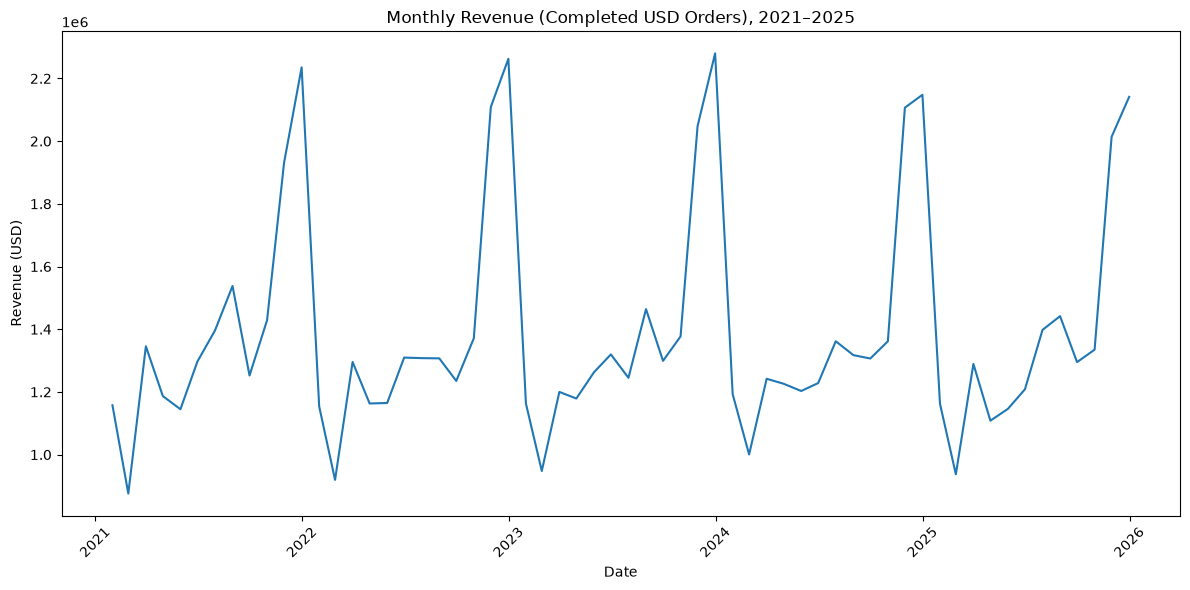

In [26]:
# Monthly Revenue Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["order_date"],
    monthly_sales["revenue"]
)

plt.title("Monthly Revenue (Completed USD Orders), 2021–2025")
plt.xlabel("Date")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Order Volume Over Time

Monthly order volume is analyzed alongside revenue to determine whether changes in sales performance are driven by changes in the number of orders.

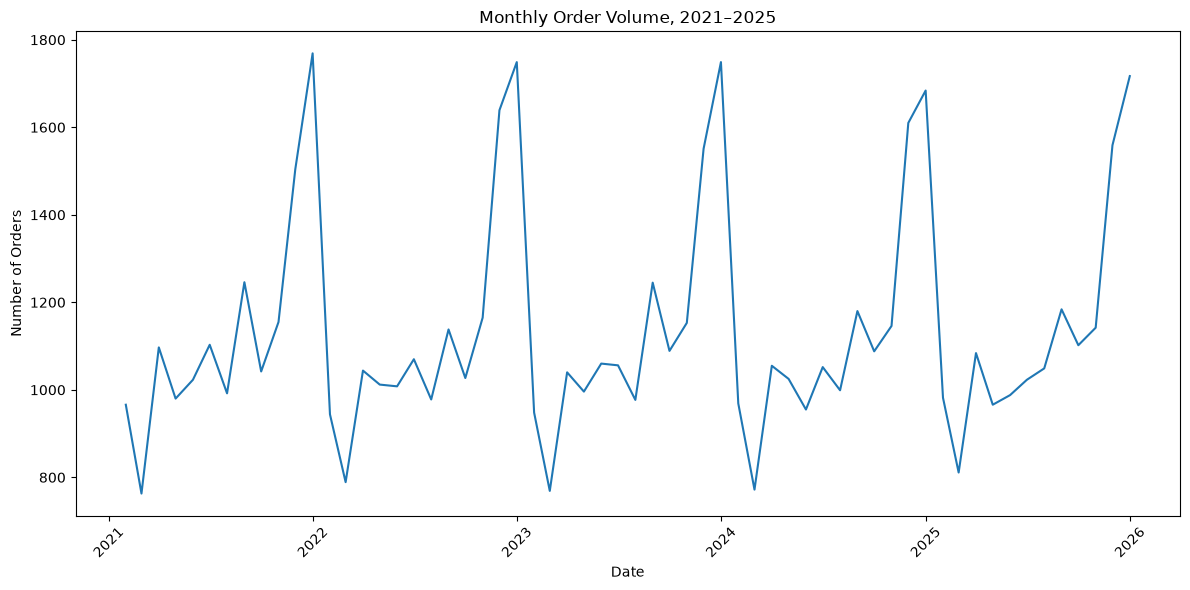

In [27]:
# Monthly Order Volume Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["order_date"],
    monthly_sales["orders"]
)

plt.title("Monthly Order Volume, 2021–2025")
plt.xlabel("Date")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [28]:
# Identify highest and lowest order-volume months

highest_orders = monthly_sales.loc[
    monthly_sales["orders"].idxmax()
]

lowest_orders = monthly_sales.loc[
    monthly_sales["orders"].idxmin()
]

print("Highest order-volume month:")
display(highest_orders.to_frame("Value"))

print("\nLowest order-volume month:")
display(lowest_orders.to_frame("Value"))

Highest order-volume month:


,Value
order_date,2021-12-31 00:00:00
revenue,2235414.73
orders,1769
profit,611157.81



Lowest order-volume month:


,Value
order_date,2021-02-28 00:00:00
revenue,875871.21
orders,763
profit,390282.17


In [29]:
# Average Monthly Orders

print(
    f"Average monthly orders: "
    f"{monthly_sales['orders'].mean():,.0f}"
)

Average monthly orders: 1,133


### Average Order Value

Average order value (AOV) measures the average net sales generated per order. Comparing AOV over time helps determine whether revenue changes are associated with changes in order volume or the value of individual orders.

In [30]:

# Calculate monthly average order value

monthly_sales["average_order_value"] = (
    monthly_sales["revenue"] / monthly_sales["orders"]
)

display(
    monthly_sales[
        ["order_date", "revenue", "orders", "average_order_value"]
    ].head(10).round(2)
)


/var/folders/md/tzw8094d2gg6wckgnvbcvmlc0000gn/T/ipykernel_58466/480458663.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,order_date,revenue,orders,average_order_value
0,2021-01-31,1157475.56,966,1198.21
1,2021-02-28,875871.21,763,1147.93
2,2021-03-31,1345617.19,1097,1226.63
3,2021-04-30,1186742.57,980,1210.96
4,2021-05-31,1144793.27,1023,1119.06
5,2021-06-30,1296895.78,1103,1175.79
6,2021-07-31,1395901.27,992,1407.16
7,2021-08-31,1537960.86,1246,1234.32
8,2021-09-30,1252338.43,1042,1201.86
9,2021-10-31,1428999.98,1155,1237.23


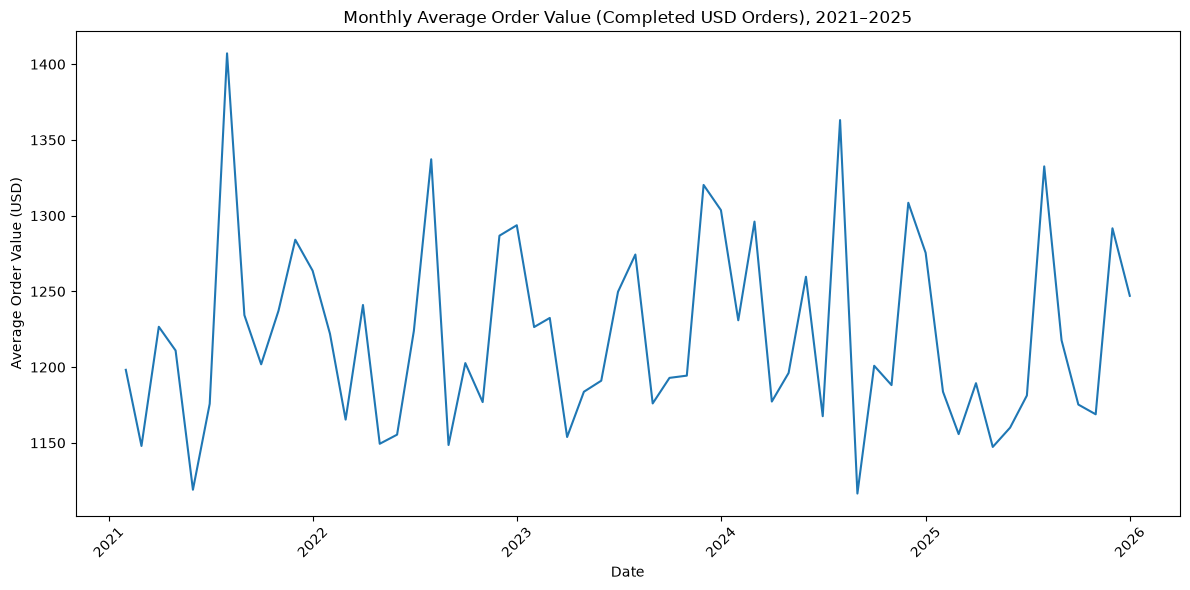

In [31]:

# Monthly Average Order Value Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["order_date"],
    monthly_sales["average_order_value"]
)

plt.title("Monthly Average Order Value (Completed USD Orders), 2021–2025")
plt.ylabel("Average Order Value (USD)")
plt.xlabel("Date")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [32]:

highest_aov = monthly_sales.loc[
    monthly_sales["average_order_value"].idxmax()
]

lowest_aov = monthly_sales.loc[
    monthly_sales["average_order_value"].idxmin()
]

print("Highest AOV month:")
display(highest_aov.to_frame("Value"))

print("\nLowest AOV month:")
display(lowest_aov.to_frame("Value"))

print(
    "\nOverall average monthly AOV:",
    round(monthly_sales["average_order_value"].mean(), 2)
)


Highest AOV month:


,Value
order_date,2021-07-31 00:00:00
revenue,1395901.27
orders,992
profit,501834.89
average_order_value,1407.158538



Lowest AOV month:


,Value
order_date,2024-08-31 00:00:00
revenue,1317507.25
orders,1180
profit,594865.25
average_order_value,1116.531568



Overall average monthly AOV: 1220.66



### Average Order Value Findings

- Monthly average order value fluctuated between $1,116.53 and $1,407.16 from 2021 through 2025.
- July 2021 recorded the highest monthly AOV at $1,407.16.
- August 2024 recorded the lowest monthly AOV at $1,116.53.
- The average monthly AOV across the five-year period was $1,220.66.
- Despite monthly fluctuations, AOV did not exhibit a clear sustained upward or downward trend.

**Key Finding:** Average order value remained relatively stable over the analysis period, suggesting that changes in monthly revenue were influenced by fluctuations in order volume as well as order value.

*Note: All financial metrics in this section reflect completed USD orders only.*


### Annual Sales Performance

Annual revenue, order volume, and profit are compared to evaluate longer-term sales performance and identify changes across the five-year period.

In [33]:

# Summarize annual sales performance
# Completed USD orders only

annual_sales = (
    sales_usd.assign(year=sales_usd["order_date"].dt.year)
    .groupby("year")
    .agg(
        revenue=("net_sales", "sum"),
        orders=("order_id", "count"),
        profit=("profit", "sum")
    )
    .reset_index()
)

annual_sales["average_order_value"] = (
    annual_sales["revenue"] / annual_sales["orders"]
)

display(annual_sales.round(2))


,year,revenue,orders,profit,average_order_value
0,2021,16789310.66,13640,6632859.89,1230.89
1,2022,16598884.07,13563,6505207.02,1223.84
2,2023,16784850.63,13633,6608323.06,1231.19
3,2024,16694636.82,13535,6598504.73,1233.44
4,2025,16476444.80,13607,6515763.22,1210.88


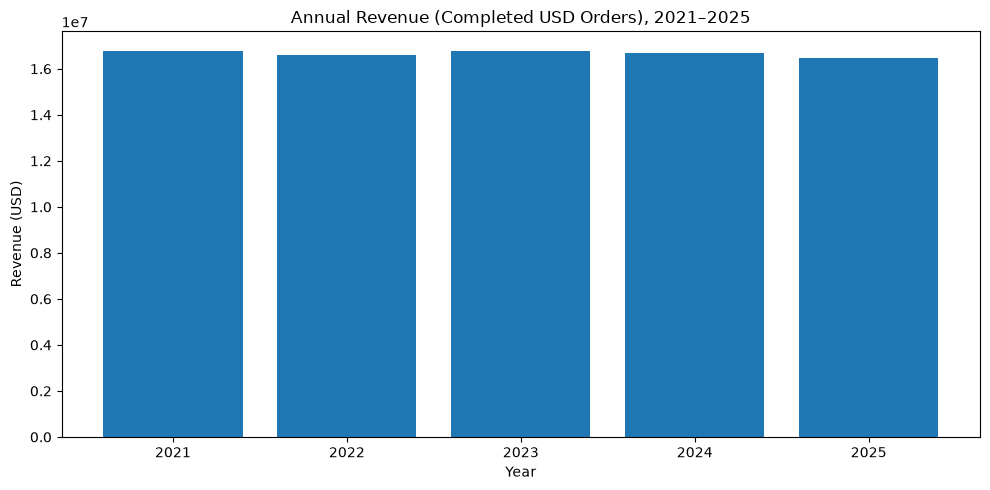

In [34]:
# Annual Revenue Visualization

plt.figure(figsize=(10, 5))

plt.bar(
    annual_sales["year"].astype(str),
    annual_sales["revenue"]
)

plt.title("Annual Revenue (Completed USD Orders), 2021–2025")
plt.xlabel("Year")
plt.ylabel("Revenue (USD)")
plt.tight_layout()

plt.show()


In [35]:

annual_sales["revenue_growth_pct"] = (
    annual_sales["revenue"].pct_change() * 100
)

display(
    annual_sales[
        ["year", "revenue", "revenue_growth_pct"]
    ].round(2)
)


,year,revenue,revenue_growth_pct
0,2021,16789310.66,NaN
1,2022,16598884.07,-1.13
2,2023,16784850.63,1.12
3,2024,16694636.82,-0.54
4,2025,16476444.80,-1.31



### Annual Sales Performance Findings

- Annual revenue remained relatively stable between 2021 and 2025, ranging from approximately $16.48 million to $16.79 million.
- Revenue declined by 1.13% in 2022, recovered by 1.12% in 2023, and decreased slightly in both 2024 and 2025.
- Annual completed order volume remained consistent, ranging from 13,535 to 13,640 orders.
- Average order value remained relatively stable, ranging from $1,210.88 to $1,233.44.

**Key Finding:** The business maintained relatively consistent annual revenue and order volume, although revenue showed a modest downward trend toward the end of the analysis period.

*Note: All financial metrics in this section reflect completed USD orders only.*


## Product Analysis

This section examines product-level sales performance to identify top-selling products, high-revenue categories, and patterns in product demand. The `order_items` dataset will provide item-level information, while `product_catalog` will provide product attributes.

In [36]:

# Inspect the product-level datasets

print("ORDER_ITEMS")
print("Shape:", order_items.shape)
print("Columns:")
print(order_items.columns.tolist())

print("\nPRODUCT_CATALOG")
print("Shape:", products.shape)
print("Columns:")
print(products.columns.tolist())


ORDER_ITEMS
Shape: (397569, 12)
Columns:
['order_id', 'product_id', 'quantity', 'unit_price', 'discount_percentage', 'discount_amount', 'gross_sales', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit']

PRODUCT_CATALOG
Shape: (1175, 9)
Columns:
['product_id', 'product_name', 'product_category', 'product_subcategory', 'brand', 'supplier', 'unit_price', 'product_cost', 'product_rating']


In [37]:

print("Order items preview:")
display(order_items.head())

print("Product catalog preview:")
display(products.head())


Order items preview:


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53


Product catalog preview:


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,1120.49,564.86,4.8
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,1282.18,695.54,2.9


In [38]:

# Inspect product attributes and product identifiers

print("Product catalog data types:")
display(products.dtypes.to_frame("Data Type"))

print("\nNumber of unique product IDs in each dataset:")
print("Order items:", order_items["product_id"].nunique())
print("Product catalog:", products["product_id"].nunique())

print("\nProduct catalog duplicate IDs:")
print(products["product_id"].duplicated().sum())


Product catalog data types:


,Data Type
product_id,str
product_name,str
product_category,str
product_subcategory,str
brand,str
supplier,str
unit_price,float64
product_cost,float64
product_rating,float64



Number of unique product IDs in each dataset:
Order items: 1175
Product catalog: 1175

Product catalog duplicate IDs:
0



### Revenue and Profit by Product Category

Product-level sales data is combined with the product catalog to compare net sales, profit, and order-item volume across product categories. This analysis identifies which categories contribute most to overall product performance.

In [39]:

# Join completed USD order items with product information

completed_usd_orders = sales_usd[["order_id"]].copy()

product_sales = (
    order_items
    .merge(
        completed_usd_orders,
        on="order_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        products,
        on="product_id",
        how="left",
        validate="many_to_one"
    )
)

print("Filtered product sales shape:", product_sales.shape)

print(
    "Unique completed USD orders:",
    product_sales["order_id"].nunique()
)

print(
    "Missing product categories:",
    product_sales["product_category"].isna().sum()
)

display(product_sales.head())


Filtered product sales shape: (195555, 20)
Unique completed USD orders: 67978
Missing product categories: 0


,order_id,product_id,quantity,unit_price_x,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost_x,profit,product_name,product_category,product_subcategory,brand,supplier,unit_price_y,product_cost_y,product_rating
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,Garmin Total client-driven task-force Medical ...,Health & Wellness,Medical Devices,Garmin,Euro Logistics,244.40,86.64,4.8
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,Tommy Hilfiger Open-architected full-range foc...,Fashion,Shoes,Tommy Hilfiger,Pacific Trade,287.13,138.35,3.0
2,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,Mars Multi-tiered homogeneous artificial intel...,Grocery,Pantry Staples,Mars,Asian Manufacturing,6.31,1.97,3.0
3,ORD-449374,PROD-000750,2,251.94,0.189728,95.60,503.88,28.58,12.07,448.93,251.82,185.04,Johnson & Johnson Self-enabling multimedia orc...,Health & Wellness,Fitness Trackers,Johnson & Johnson,Alibaba,251.94,125.91,2.8
4,ORD-567636,PROD-000639,1,280.19,0.016780,4.70,280.19,19.28,6.37,301.14,172.77,122.00,Bridgestone Customer-focused dynamic Internet ...,Automotive,Car Accessories,Bridgestone,North American Supply,280.19,172.77,4.6


In [40]:

# Revenue and profit by product category
# Completed USD orders only

category_sales = (
    product_sales
    .groupby("product_category")
    .agg(
        total_revenue=("net_sales", "sum"),
        total_profit=("profit", "sum"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
)

category_sales["profit_margin_pct"] = (
    category_sales["total_profit"]
    / category_sales["total_revenue"]
    * 100
)

category_sales = category_sales.sort_values(
    "total_revenue", ascending=False
)

display(category_sales.round(2))


,product_category,total_revenue,total_profit,units_sold,profit_margin_pct
4,Electronics,19344394.53,5903977.06,27680,30.52
10,Jewelry,12010610.20,4453286.90,24399,37.08
9,Home Appliances,11899156.41,4535995.43,28328,38.12
0,Automotive,7755910.29,2788039.66,28842,35.95
13,Sports & Outdoors,7388835.41,3163304.12,32317,42.81
8,Home & Kitchen,5173102.25,2293096.17,24828,44.33
1,Baby & Kids,4567938.05,2129719.57,27014,46.62
7,Health & Wellness,4367987.30,1889803.58,30863,43.26
11,Office Supplies,4243918.58,2079896.75,28995,49.01
5,Fashion,3511070.79,1625393.24,24328,46.29


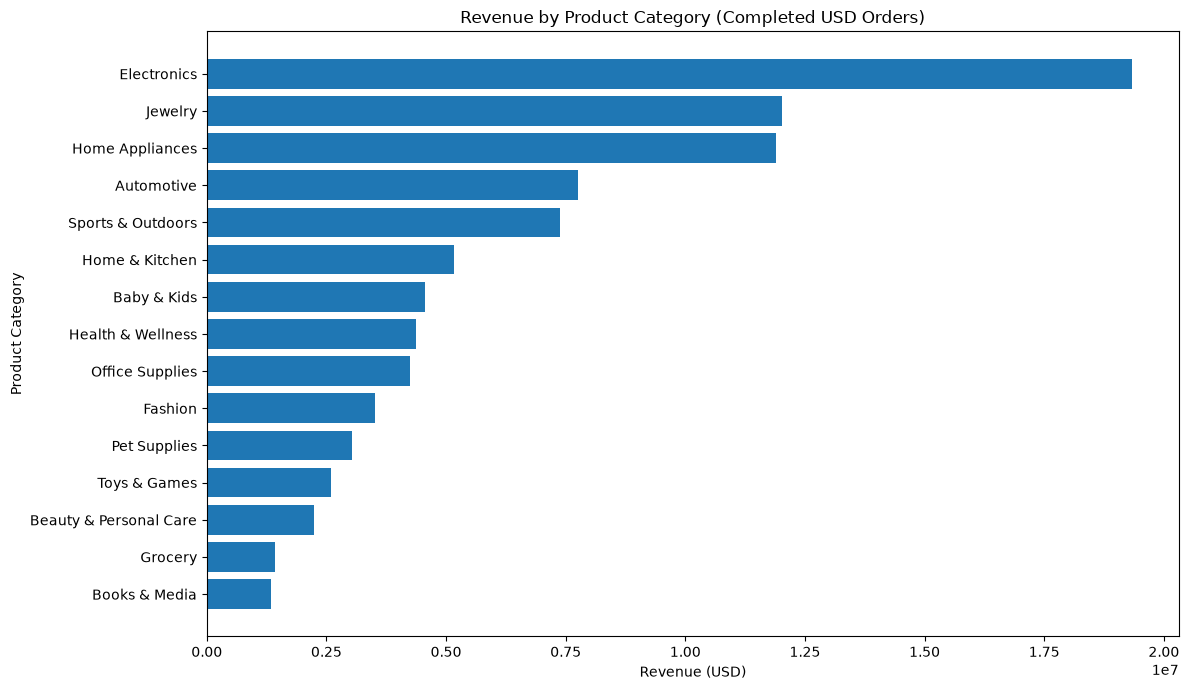

In [41]:

# Net sales by product category visualization

category_plot = category_sales.sort_values(
    "total_revenue",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    category_plot["product_category"],
    category_plot["total_revenue"]
)

plt.title("Revenue by Product Category (Completed USD Orders)")
plt.xlabel("Revenue (USD)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.show()


### Top 10 Products by Net Sales

Individual products are ranked by total item-level net sales to identify the products contributing most to product revenue. Profit and units sold are included to provide additional business context.

In [42]:

# Rank products by total net sales

top_products = (
    product_sales
    .groupby(
        ["product_id", "product_name", "product_category"],
        as_index=False
    )
    .agg(
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        units_sold=("quantity", "sum")
    )
    .sort_values("net_sales", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_products.index = top_products.index + 1

display(top_products.round(2))


,product_id,product_name,product_category,net_sales,profit,units_sold
1,PROD-000074,Asus Configurable upward-trending matrix TVs,Electronics,476863.12,131854.88,417
2,PROD-000051,HP Versatile actuating budgetary management Sm...,Electronics,466484.89,169182.40,391
3,PROD-000062,OnePlus Adaptive uniform success Gaming Consoles,Electronics,449044.38,163049.56,385
4,PROD-000077,OnePlus Switchable methodical neural-net TVs,Electronics,442142.84,129099.07,366
5,PROD-000065,Xiaomi Self-enabling exuding productivity Gami...,Electronics,428252.40,129730.86,346
6,PROD-000043,OnePlus Streamlined modular infrastructure Sma...,Electronics,418549.42,99634.47,374
7,PROD-000024,Asus Re-engineered content-based strategy Tablets,Electronics,413079.44,109973.45,311
8,PROD-000012,LG Reverse-engineered even-keeled workforce Sm...,Electronics,397764.75,81451.80,317
9,PROD-000056,HP Function-based neutral access Cameras,Electronics,389224.88,136924.81,346
10,PROD-000018,Sony Cross-platform heuristic hardware Laptops,Electronics,383330.15,76814.37,367


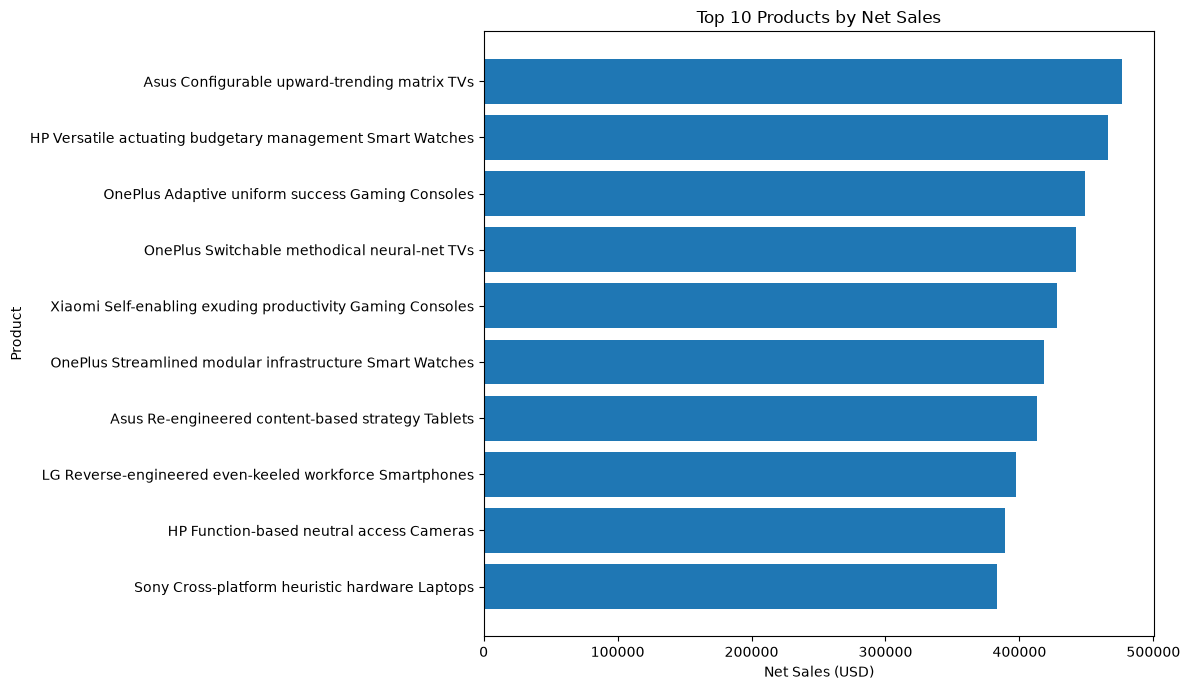

In [43]:

# Top 10 products by net sales visualization

top_products_plot = top_products.sort_values(
    "net_sales",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_products_plot["product_name"],
    top_products_plot["net_sales"]
)

plt.title("Top 10 Products by Net Sales")
plt.xlabel("Net Sales (USD)")
plt.ylabel("Product")
plt.tight_layout()

plt.show()


### Top 10 Products by Profit

Products are ranked by total item-level profit to identify which products contribute most to profitability. Comparing profit rankings with net-sales rankings helps distinguish high-revenue products from high-profit products.

In [44]:

# Rank products by total profit

top_profit_products = (
    product_sales
    .groupby(
        ["product_id", "product_name", "product_category"],
        as_index=False
    )
    .agg(
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        units_sold=("quantity", "sum")
    )
    .sort_values("profit", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_profit_products.index = top_profit_products.index + 1

display(top_profit_products.round(2))


,product_id,product_name,product_category,net_sales,profit,units_sold
1,PROD-000996,Messika Networked disintermediate knowledge us...,Jewelry,345888.13,177778.64,414
2,PROD-000051,HP Versatile actuating budgetary management Sm...,Electronics,466484.89,169182.40,391
3,PROD-000062,OnePlus Adaptive uniform success Gaming Consoles,Electronics,449044.38,163049.56,385
4,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,361777.08,141621.66,387
5,PROD-001003,Tous Diverse impactful software Chains,Jewelry,261805.66,139503.08,329
6,PROD-000056,HP Function-based neutral access Cameras,Electronics,389224.88,136924.81,346
7,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,370111.39,136667.25,334
8,PROD-000152,Miele Expanded systemic productivity Toasters,Home Appliances,265754.82,136403.22,406
9,PROD-000028,Dell Multi-tiered even-keeled knowledgebase Ta...,Electronics,375748.45,135844.47,417
10,PROD-000952,Mikimoto Monitored zero administration website...,Jewelry,273113.06,133475.76,348


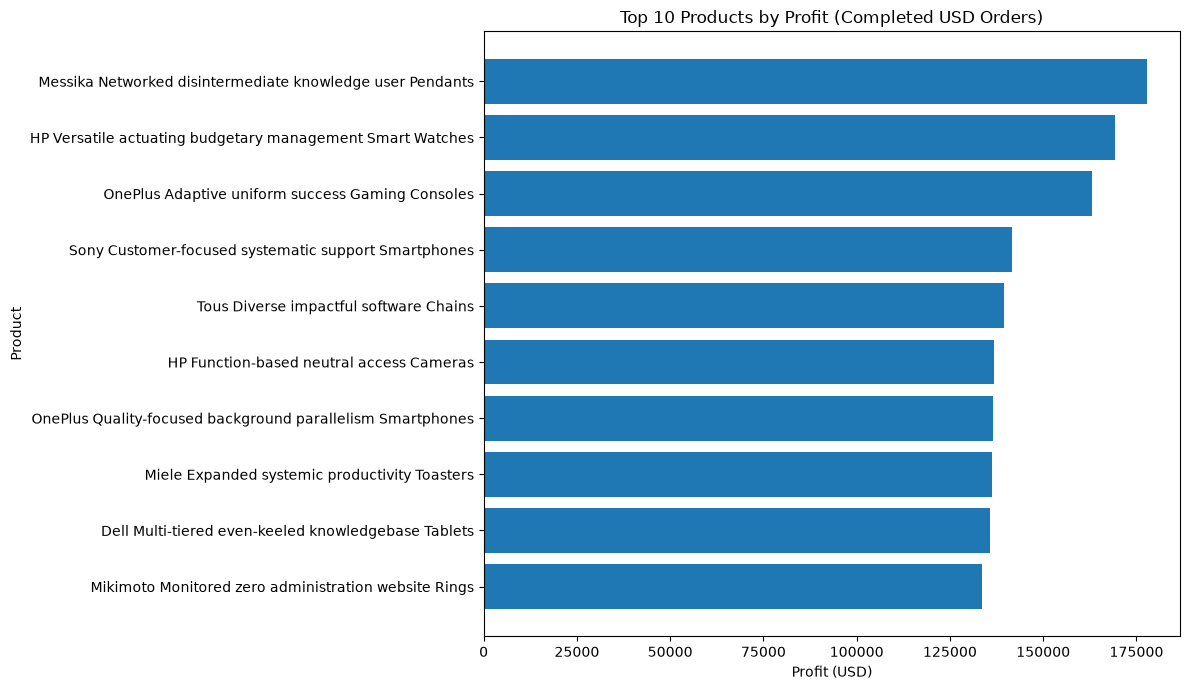

In [45]:

# Top 10 products by profit visualization

profit_plot = top_profit_products.sort_values(
    "profit",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    profit_plot["product_name"],
    profit_plot["profit"]
)

plt.title("Top 10 Products by Profit (Completed USD Orders)")
plt.xlabel("Profit (USD)")
plt.ylabel("Product")
plt.tight_layout()

plt.show()


### Top Products by Profit Findings

- Electronics accounts for 7 of the top 10 most profitable products, while Jewelry accounts for the remaining 3.
- OnePlus Gaming Consoles generated the highest total profit at approximately 376.8K.
- Jewelry products demonstrate strong profitability, with one product ranking second overall despite generating less net sales than several Electronics products.
- The product with the highest net sales ranked ninth in profit, demonstrating that revenue alone does not determine profitability.
- These results suggest that product costs, pricing, and discounts should be considered alongside sales volume when evaluating product performance.

*Note: Monetary values are reported in the dataset's units because its currency conversion methodology is undocumented. These findings describe observed relationships and do not establish that discounts alone cause lower profitability.*

### Profit Margin by Product Category

This analysis compares profit margins across product categories to identify which categories retain the greatest share of net sales as profit.

In [46]:
# Calculate profit margin by product category

category_sales["profit_margin_percentage"] = (
    category_sales["total_profit"] / category_sales["total_revenue"]
) * 100

category_margin = category_sales.sort_values(
    "profit_margin_percentage",
    ascending=False
)

display(
    category_margin[
        [
            "product_category",
            "total_revenue",
            "total_profit",
            "profit_margin_percentage"
        ]
    ].round(2)
)

,product_category,total_revenue,total_profit,profit_margin_percentage
6,Grocery,1420306.82,747747.41,52.65
2,Beauty & Personal Care,2234334.77,1110718.12,49.71
3,Books & Media,1340885.81,663648.59,49.49
11,Office Supplies,4243918.58,2079896.75,49.01
14,Toys & Games,2601148.71,1261083.54,48.48
12,Pet Supplies,3034006.96,1456135.03,47.99
1,Baby & Kids,4567938.05,2129719.57,46.62
5,Fashion,3511070.79,1625393.24,46.29
8,Home & Kitchen,5173102.25,2293096.17,44.33
7,Health & Wellness,4367987.30,1889803.58,43.26


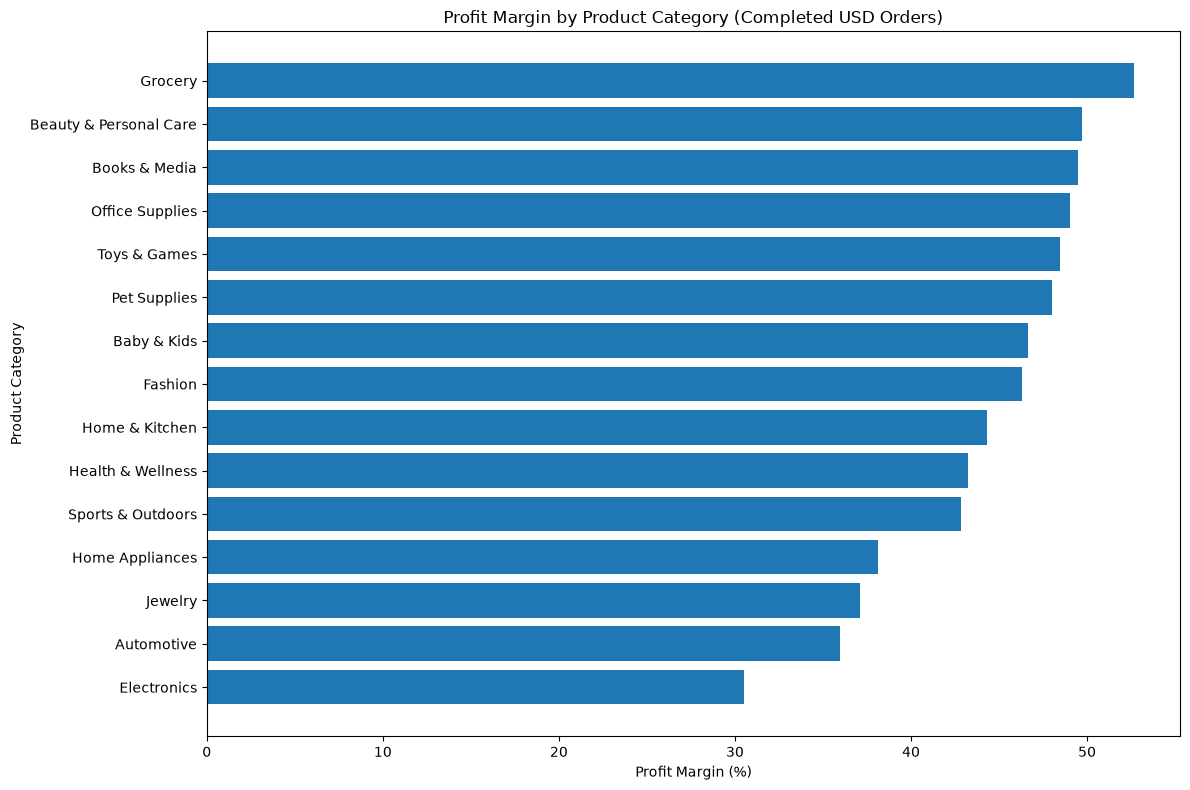

In [47]:
# Profit margin by product category visualization

margin_plot = category_margin.sort_values(
    "profit_margin_percentage",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    margin_plot["product_category"],
    margin_plot["profit_margin_percentage"]
)

plt.title("Profit Margin by Product Category (Completed USD Orders)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

### Profit Margin by Category Findings

- **Grocery had the highest profit margin at 52.65%**, while Electronics had the lowest at 30.52%.
- **Electronics generated the highest total net sales and profit**, contributing approximately $19.34 million in revenue and $5.90 million in profit.
- **Grocery and Beauty & Personal Care demonstrated strong profitability**, with margins of 52.65% and 49.71%, respectively.
- **Jewelry and Home Appliances generated substantial revenue**, with profit margins of 37.08% and 38.12%, respectively.
- **Revenue and profitability varied across product categories**, demonstrating the importance of evaluating both total profit and profit margin when assessing category performance.

**Key Finding:** Electronics was the largest revenue contributor, but categories such as Grocery and Beauty & Personal Care retained a greater percentage of their net sales as profit.

*Note: Financial metrics reflect product-level transactions associated with completed USD orders from 2021–2025.*

### Product Analysis Summary

The product analysis identified differences in sales performance and profitability across product categories and individual products.

- **Electronics generated the highest category revenue**, totaling $19.34 million, followed by Jewelry ($12.01 million) and Home Appliances ($11.90 million).
- **Electronics also generated the highest total profit**, at $5.90 million, despite having the lowest category profit margin (30.52%).
- **Grocery achieved the highest profit margin** at 52.65%, followed by Beauty & Personal Care (49.71%) and Books & Media (49.49%).
- The highest-revenue products were concentrated in electronics, including gaming consoles, televisions, smart watches, and tablets.
- The top 10 products by profit differed from the top 10 by revenue, indicating that high sales revenue does not necessarily correspond to the highest profitability.

**Key Finding:** Electronics is the strongest category by revenue and total profit, while lower-revenue categories such as Grocery demonstrate higher profit margins. This highlights the importance of evaluating both revenue contribution and profitability when assessing product performance.

*Note: All financial metrics in this section reflect completed USD orders only.*

## Customer Analysis

This section examines customer purchasing behavior, spending patterns, and repeat purchasing activity. The analysis will identify high-value customers, compare new and returning customers, and explore customer characteristics that may influence sales.

### Customer Data Overview

This section reviews the customer dataset to understand its structure, the number of unique customers, and the distribution of orders across customers before analyzing purchasing behavior.

In [48]:
# Review customer data

print("Total orders:", sales["order_id"].nunique())
print("Unique customers:", sales["customer_id"].nunique())
print("Average orders per customer:",
      round(sales["order_id"].nunique() / sales["customer_id"].nunique(), 2))

print("\nCustomer type distribution:")
display(sales["customer_type"].value_counts(dropna=False))

print("\nRepeat customer flag distribution:")
display(sales["is_repeat_customer"].value_counts(dropna=False))

Total orders: 138116
Unique customers: 24911
Average orders per customer: 5.54

Customer type distribution:


customer_type
Loyal        129447
Returning      8335
New             334
Name: count, dtype: int64


Repeat customer flag distribution:


is_repeat_customer
True     137782
False       334
Name: count, dtype: int64

### Customer Classification Validation

This analysis checks whether customer classifications remain consistent across orders and compares the dataset's customer-type labels with actual order frequency.

In [49]:
# Summarize orders and classifications by customer

customer_summary = (
    sales.groupby("customer_id")
    .agg(
        order_count=("order_id", "nunique"),
        customer_types=("customer_type", "nunique"),
        repeat_flags=("is_repeat_customer", "nunique"),
        customer_order_count_values=("customer_order_count", "nunique")
    )
    .reset_index()
)

print("Customers with multiple customer types:",
      (customer_summary["customer_types"] > 1).sum())

print("Customers with inconsistent repeat flags:",
      (customer_summary["repeat_flags"] > 1).sum())

print("Customers with inconsistent customer order counts:",
      (customer_summary["customer_order_count_values"] > 1).sum())

print("\nDistribution of orders per customer:")
display(
    customer_summary["order_count"]
    .value_counts()
    .sort_index()
    .rename_axis("orders_per_customer")
    .reset_index(name="number_of_customers")
)

Customers with multiple customer types: 0
Customers with inconsistent repeat flags: 0
Customers with inconsistent customer order counts: 0

Distribution of orders per customer:


,orders_per_customer,number_of_customers
0,1,524
1,2,1543
2,3,2766
3,4,3912
4,5,4288
5,6,3942
6,7,3109
7,8,2169
8,9,1299
9,10,744


### Customer Spending Analysis

This analysis measures total customer spending, order frequency, and average order value per customer to identify high-value customers and understand purchasing behavior.

In [50]:

# Aggregate completed USD order-level sales by customer

customer_spending = (
    sales_usd.groupby("customer_id")
    .agg(
        total_spending=("net_sales", "sum"),
        total_orders=("order_id", "nunique"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

customer_spending["average_order_value"] = (
    customer_spending["total_spending"]
    / customer_spending["total_orders"]
)

print("Customer spending summary (Completed USD Orders):")
display(
    customer_spending[
        ["total_spending", "total_orders", "average_order_value", "total_profit"]
    ].describe().round(2)
)

print("\nTop 10 customers by total spending (USD):")
display(
    customer_spending
    .sort_values("total_spending", ascending=False)
    .head(10)
    .round(2)
)


Customer spending summary (Completed USD Orders):


,total_spending,total_orders,average_order_value,total_profit
count,14783.00,14783.00,14783.00,14783.00
mean,5637.84,4.60,1224.12,2222.87
std,3518.45,2.08,606.01,1405.79
min,22.55,1.00,22.55,-1117.39
25%,2986.62,3.00,818.60,1170.28
50%,5051.12,4.00,1140.46,1985.87
75%,7688.30,6.00,1528.01,3048.06
max,27671.95,15.00,8874.15,11322.89



Top 10 customers by total spending (USD):


,customer_id,total_spending,total_orders,total_profit,average_order_value
10222,CUST-017251,27671.95,14,9797.86,1976.57
4105,CUST-006857,24552.26,9,8609.30,2728.03
4690,CUST-007827,24527.64,10,9259.58,2452.76
14487,CUST-024503,24463.31,7,8860.31,3494.76
7831,CUST-013167,23754.53,12,8110.09,1979.54
7273,CUST-012262,23486.69,10,11322.89,2348.67
107,CUST-000165,23073.48,12,8035.16,1922.79
5786,CUST-009693,22342.38,7,8688.62,3191.77
13683,CUST-023134,21608.90,10,6374.65,2160.89
13271,CUST-022441,21400.25,15,9363.23,1426.68


### Customer Spending Distribution

These visualizations examine how customer spending is distributed and whether customers who place more orders tend to generate higher total spending.

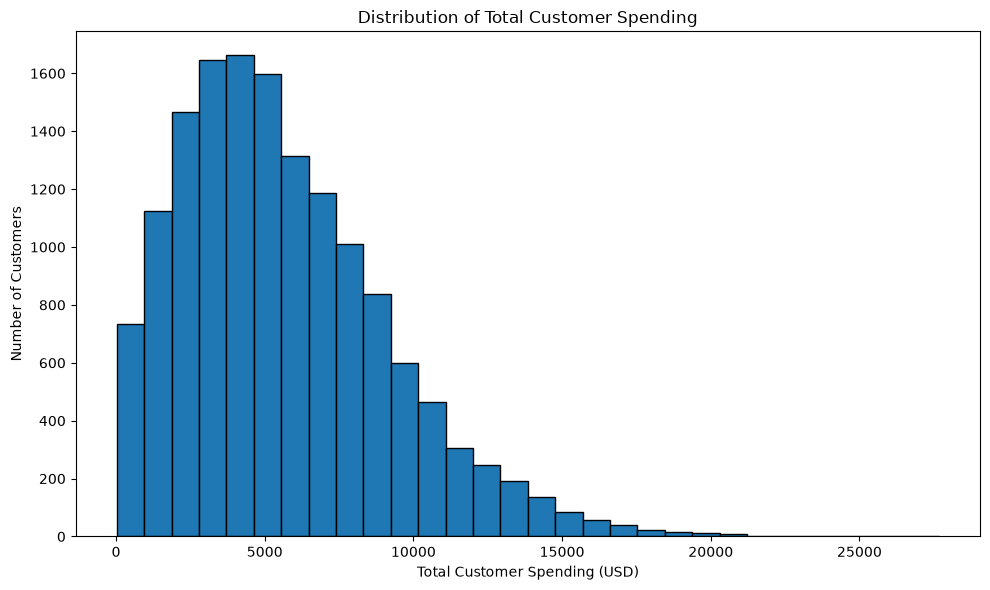

In [51]:
# Distribution of Total Customer Spending

plt.figure(figsize=(10, 6))

plt.hist(
    customer_spending["total_spending"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Total Customer Spending")
plt.xlabel("Total Customer Spending (USD)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

**Key Finding — Distribution of Total Customer Spending**

Customer spending is concentrated toward the lower end of the distribution, with the histogram's highest bin occurring around 5,000 in total spending and approximately 2,500 customers in that bin. This count represents customers within that spending interval, rather than all customers spending exactly 5,000. The distribution suggests that most customers spend within a moderate range, while fewer customers have higher total spending. This highlights an opportunity to identify and retain high-value customers.

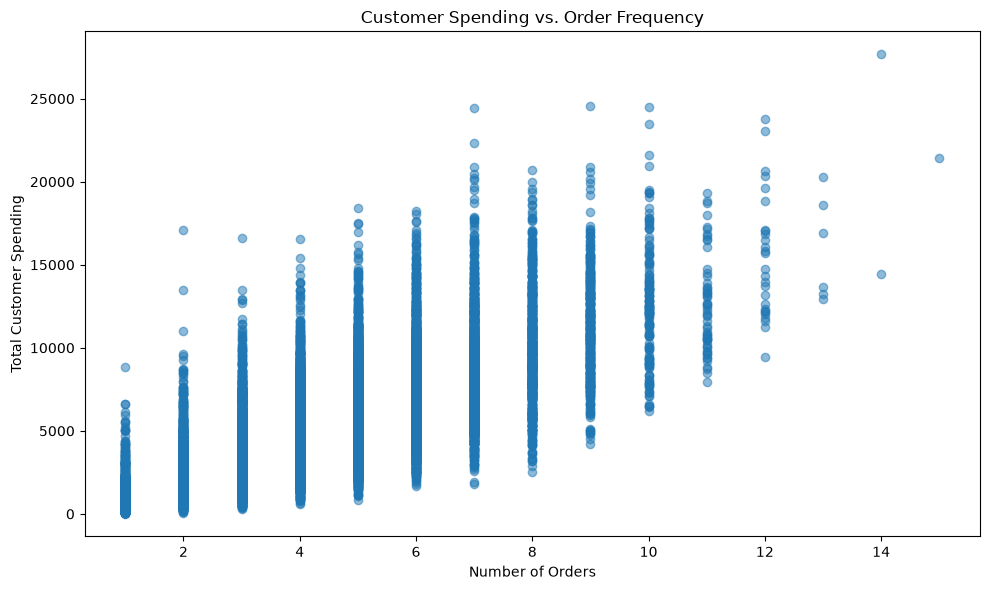

In [52]:
# Compare order frequency with total customer spending

plt.figure(figsize=(10, 6))

plt.scatter(
    customer_spending["total_orders"],
    customer_spending["total_spending"],
    alpha=0.5
)

plt.title("Customer Spending vs. Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Total Customer Spending")

plt.tight_layout()
plt.show()

**Key Finding — Customer Spending vs. Order Frequency**

The scatter plot shows a positive relationship between order frequency and total customer spending: customers who place more orders generally spend more overall. Most customers follow this upward trend, and the outliers are relatively close to the main cluster of points. This suggests that repeat purchasing is an important contributor to customer value.

### New vs. Returning Customer Analysis

This analysis compares customer groups by customer count, order volume, and net sales to understand how new and repeat customers contribute to overall business performance.

In [53]:

# Summarize customer groups using completed USD orders

customer_group_summary = (
    sales_usd.groupby("customer_type")
    .agg(
        unique_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        net_sales=("net_sales", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

customer_group_summary["sales_percentage"] = (
    customer_group_summary["net_sales"]
    / customer_group_summary["net_sales"].sum()
) * 100

customer_group_summary["orders_per_customer"] = (
    customer_group_summary["total_orders"]
    / customer_group_summary["unique_customers"]
)

display(customer_group_summary.round(2))


,customer_type,unique_customers,total_orders,net_sales,total_profit,sales_percentage,orders_per_customer
0,Loyal,12664,63769,78297402.26,30898436.85,93.94,5.04
1,New,163,163,216414.40,87584.83,0.26,1.00
2,Returning,1956,4046,4830310.32,1874636.24,5.80,2.07


### Net Sales Contribution by Customer Type

This visualization compares the percentage of total net sales generated by Loyal, Returning, and New customers to show how each group contributes to overall business performance.

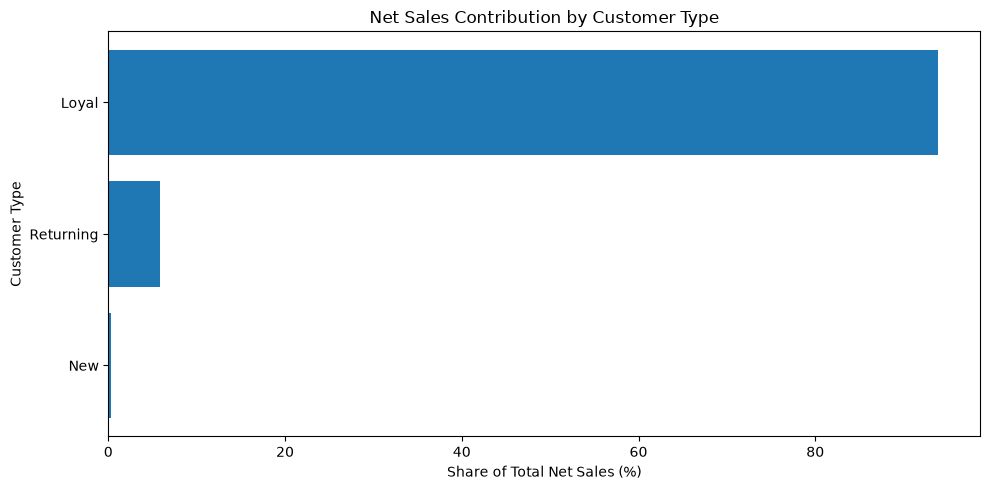

In [54]:
# Net Sales Contribution by Customer Type

sales_mix = customer_group_summary.sort_values(
    "sales_percentage",
    ascending=True
)

plt.figure(figsize=(10, 5))

plt.barh(
    sales_mix["customer_type"],
    sales_mix["sales_percentage"]
)

plt.title("Net Sales Contribution by Customer Type")
plt.xlabel("Share of Total Net Sales (%)")
plt.ylabel("Customer Type")

plt.tight_layout()
plt.show()

### Customer Sales Contribution Findings

- **Loyal customers generated 93.94% of total net sales**, contributing approximately $78.30 million across 63,769 completed USD orders.
- **Returning customers contributed 5.80% of total net sales**, generating approximately $4.83 million across 4,046 orders.
- **New customers accounted for 0.26% of total net sales**, contributing approximately $216,414 across 163 orders.
- **Loyal customers represented the largest customer segment**, with 12,664 unique customers, compared with 1,956 Returning customers and 163 New customers.
- **Loyal customers also had the highest purchase frequency**, averaging 5.04 completed USD orders per customer.

**Key Finding:** Loyal customers are the primary contributors to revenue, highlighting the importance of retaining and engaging existing customers.

*Note: Financial metrics reflect completed USD orders from 2021–2025. Customer classifications are based on the dataset's existing customer type labels.*

### Customer Spending by Type

This analysis compares spending and purchasing frequency across customer types to determine whether differences in sales contribution are associated with customer counts, order frequency, or average order value.

In [55]:

# Compare spending metrics by customer type
# Completed USD orders only

customer_type_spending = (
    sales_usd.groupby("customer_type")
    .agg(
        unique_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_net_sales=("net_sales", "sum")
    )
    .reset_index()
)

customer_type_spending["spending_per_customer"] = (
    customer_type_spending["total_net_sales"]
    / customer_type_spending["unique_customers"]
)

customer_type_spending["average_order_value"] = (
    customer_type_spending["total_net_sales"]
    / customer_type_spending["total_orders"]
)

customer_type_spending["orders_per_customer"] = (
    customer_type_spending["total_orders"]
    / customer_type_spending["unique_customers"]
)

display(customer_type_spending.round(2))


,customer_type,unique_customers,total_orders,total_net_sales,spending_per_customer,average_order_value,orders_per_customer
0,Loyal,12664,63769,78297402.26,6182.68,1227.83,5.04
1,New,163,163,216414.40,1327.70,1327.70,1.00
2,Returning,1956,4046,4830310.32,2469.48,1193.85,2.07


**Key Finding — Customer Spending by Type**

- **Loyal customers had the highest average spending per customer** at $6,182.68, compared with $2,469.48 for Returning customers and $1,327.70 for New customers.
- **New customers had the highest average order value** at $1,327.70, followed by Loyal customers ($1,227.83) and Returning customers ($1,193.85).
- **Loyal customers purchased most frequently**, averaging 5.04 completed USD orders per customer, compared with 2.07 for Returning customers and 1.00 for New customers.
- **Higher purchase frequency contributed to greater cumulative spending among Loyal customers**, even though New customers had the highest average order value.
- **Returning customers demonstrated intermediate purchasing behavior**, spending more per customer than New customers but substantially less than Loyal customers.

**Key Finding:** Loyal customers generated the highest cumulative spending primarily through more frequent purchases, while New customers recorded the highest average order value.

*Note: Financial metrics reflect completed USD orders from 2021–2025. Customer types are based on the dataset's existing classifications and do not necessarily represent lifetime purchasing behavior.*

### Customer Analysis Summary

The customer analysis revealed that repeat purchasing is a major contributor to overall sales, with meaningful differences in spending behavior across customer groups.

- **Loyal customers generated 93.94% of total revenue**, contributing approximately $78.30 million from 63,769 completed USD orders.
- **Loyal customers had the highest spending per customer**, averaging $6,182.68, compared with $2,469.48 for Returning customers and $1,327.70 for New customers.
- **New customers had the highest average order value** at $1,327.70, followed by Loyal customers ($1,227.83) and Returning customers ($1,193.85).
- **Purchase frequency varied by customer type.** Loyal customers averaged 5.04 completed USD orders per customer, compared with 2.07 for Returning customers and 1.00 for New customers.
- Across all 14,783 customers with completed USD orders, median spending was $5,051.12, while average spending was $5,637.84.

**Key Finding:** Loyal customers are the primary drivers of revenue, largely because of their higher purchase frequency and cumulative spending rather than having the highest average order value.

*Note: Financial metrics reflect completed USD orders only. Customer types are based on the dataset's existing classifications, and group-level metrics do not necessarily represent lifetime customer behavior.*

## Profitability Analysis

This section evaluates how effectively the business converts net sales into profit. It examines overall profitability, changes in profit over time, and the relationship between discounts and profit to identify potential opportunities to improve financial performance.

In [56]:

# Calculate overall profitability metrics
# Completed USD orders only

total_net_sales = sales_usd["net_sales"].sum()
total_profit = sales_usd["profit"].sum()

overall_profit_margin = (total_profit / total_net_sales) * 100

print(f"Total Net Sales (USD): ${total_net_sales:,.2f}")
print(f"Total Profit (USD): ${total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")


Total Net Sales (USD): $83,344,126.98
Total Profit (USD): $32,860,657.92
Overall Profit Margin: 39.43%


**Key Finding — Overall Profitability**

- **Total net sales reached $83.34 million**, generating $32.86 million in profit across 67,978 completed USD orders.
- **The overall profit margin was 39.43%**, indicating that approximately $0.39 in profit was generated for every $1.00 in net sales.
- **Monthly profitability varied throughout the analysis period**, with profit margins influenced by differences in order activity, discount amounts, and product sales composition.
- **Higher discount amounts were associated with lower average profit margins**, particularly among orders receiving discounts exceeding $200.
- **Seasonal profitability patterns were evident**, with November and December recording the lowest calendar-month profit margins at 27.30% and 27.36%, respectively.

**Key Finding:** The business maintained an overall profit margin of 39.43%, although profitability varied across discount groups and calendar months.

*Note: Financial metrics reflect completed USD orders from 2021–2025. Relationships between discounts and profitability are observational and do not establish causation.*

In [57]:

# Calculate monthly profitability
# Completed USD orders only

monthly_profitability = (
    sales_usd.set_index("order_date")
    .resample("ME")
    .agg(
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_profitability["profit_margin_percentage"] = (
    monthly_profitability["profit"]
    / monthly_profitability["net_sales"]
) * 100

display(monthly_profitability.head().round(2))


/var/folders/md/tzw8094d2gg6wckgnvbcvmlc0000gn/T/ipykernel_58466/3586380401.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_profitability.head().round(2))


,order_date,net_sales,profit,orders,profit_margin_percentage
0,2021-01-31,1157475.56,520317.06,966,44.95
1,2021-02-28,875871.21,390282.17,763,44.56
2,2021-03-31,1345617.19,602384.71,1097,44.77
3,2021-04-30,1186742.57,532847.75,980,44.90
4,2021-05-31,1144793.27,516173.03,1023,45.09


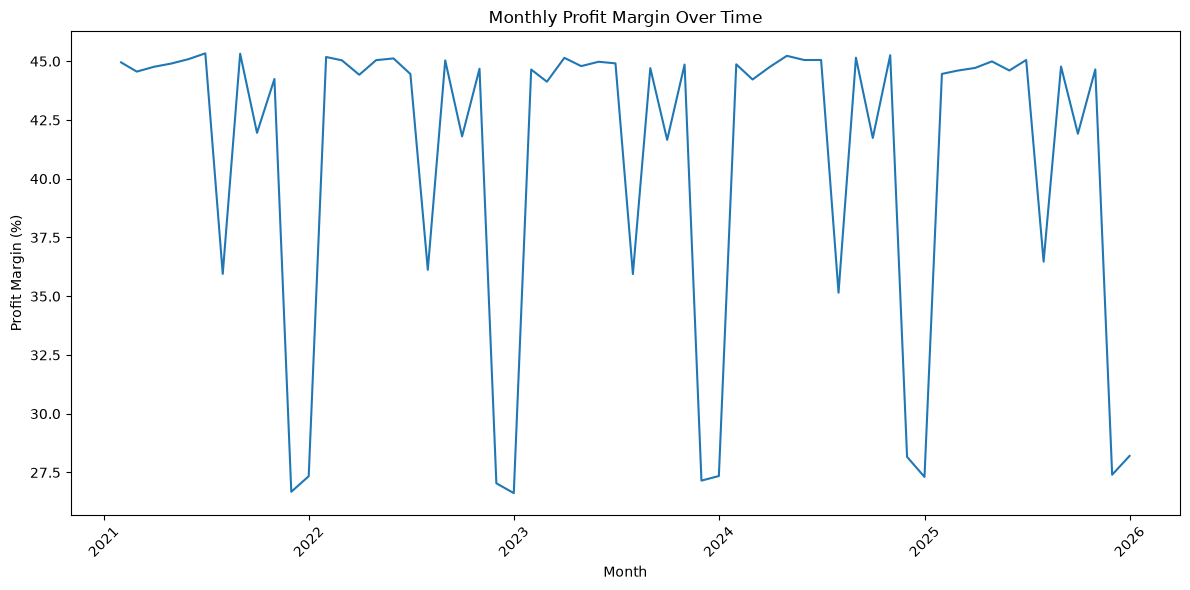

In [58]:
# Monthly Profit Margin Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_profitability["order_date"],
    monthly_profitability["profit_margin_percentage"]
)

plt.title("Monthly Profit Margin Over Time")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Key Finding — Monthly Profit Margin Trends**

Monthly profit margins show a recurring seasonal pattern, with higher profitability during much of the year and substantial declines during the holiday shopping season.

Across 2021–2025, the combined calendar-month profit margins remained near 45% for most months. However, margins declined to 35.93% in July, 27.30% in November, and 27.36% in December.

November and December also recorded the highest average discount amounts and order volumes, suggesting a relationship between seasonal purchasing activity, discounting, and profitability.

**Key Finding:** Profitability was considerably lower during November and December, highlighting the importance of evaluating whether increased holiday sales volume offsets reduced profit margins.

*Note: Calendar-month figures combine the corresponding months across 2021–2025. The relationship between seasonal discounting and profitability is observational and does not establish causation.*

In [59]:
[col for col in sales.columns if "discount" in col.lower()]

['discount_amount']

In [60]:

# Review discount amounts
# Completed USD orders only

print("Discount summary (Completed USD Orders):")
display(sales_usd["discount_amount"].describe().round(2))

print("\nOrders with zero discount:",
      (sales_usd["discount_amount"] == 0).sum())

print("Orders with missing discount:",
      sales_usd["discount_amount"].isna().sum())


Discount summary (Completed USD Orders):


count    67978.00
mean       273.16
std        394.92
min          0.00
25%         51.03
50%        132.94
75%        319.29
max       4833.87
Name: discount_amount, dtype: float64


Orders with zero discount: 1
Orders with missing discount: 0


In [61]:

# Calculate order-level profit margin
# Completed USD orders only

sales_usd["order_profit_margin_percentage"] = (
    sales_usd["profit"] / sales_usd["net_sales"]
) * 100

# Create discount groups based on discount amount
sales_usd["discount_group"] = pd.cut(
    sales_usd["discount_amount"],
    bins=[-0.01, 0, 50, 100, 200, float("inf")],
    labels=[
        "No Discount",
        "0.01–50",
        "50.01–100",
        "100.01–200",
        "Over 200"
    ]
)

discount_analysis = (
    sales_usd.groupby("discount_group", observed=False)
    .agg(
        order_count=("order_id", "nunique"),
        average_discount=("discount_amount", "mean"),
        average_net_sales=("net_sales", "mean"),
        average_profit=("profit", "mean"),
        average_profit_margin=("order_profit_margin_percentage", "mean")
    )
    .reset_index()
)

display(discount_analysis.round(2))


,discount_group,order_count,average_discount,average_net_sales,average_profit,average_profit_margin
0,No Discount,1,0.00,123.67,67.62,54.68
1,0.01–50,16702,23.73,366.05,183.79,49.22
2,50.01–100,11616,73.48,758.17,363.50,46.86
3,100.01–200,14095,144.63,1168.07,534.02,44.31
4,Over 200,25564,597.75,2032.52,705.74,33.67


**Key Finding — Discount Amount and Profitability**

1. Average profit margins decrease as discount amounts increase. Orders discounted by $0.01–$50 averaged a 49.22% profit margin, compared with 33.67% for orders discounted by more than $200.

2. Average profit per order increases with discount amounts. Orders receiving discounts over $200 generated an average profit of $705.74, compared with $183.79 for orders discounted by $0.01–$50.

3. The largest discount group contains the most orders. The Over $200 group accounts for 25,564 orders, approximately 37.6% of completed USD orders.

4. The No Discount group is too small for meaningful comparison. It contains only one order.

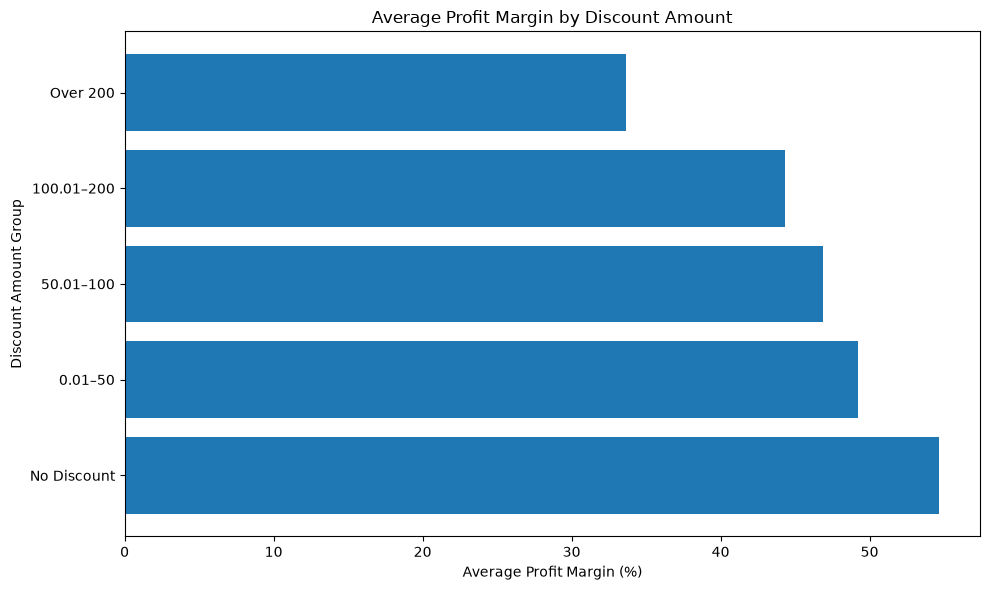

In [62]:
plt.figure(figsize=(10, 6))

plt.barh(
    discount_analysis["discount_group"].astype(str),
    discount_analysis["average_profit_margin"]
)

plt.title("Average Profit Margin by Discount Amount")
plt.xlabel("Average Profit Margin (%)")
plt.ylabel("Discount Amount Group")
plt.tight_layout()
plt.show()

In [63]:

# Calculate monthly discount and profitability trends
# Completed USD orders only

monthly_discount_analysis = (
    sales_usd.set_index("order_date")
    .resample("ME")
    .agg(
        average_discount=("discount_amount", "mean"),
        total_discount=("discount_amount", "sum"),
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_discount_analysis["profit_margin_percentage"] = (
    monthly_discount_analysis["profit"]
    / monthly_discount_analysis["net_sales"]
) * 100

display(monthly_discount_analysis.head().round(2))


/var/folders/md/tzw8094d2gg6wckgnvbcvmlc0000gn/T/ipykernel_58466/2882694334.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_discount_analysis.head().round(2))


,order_date,average_discount,total_discount,net_sales,profit,orders,profit_margin_percentage
0,2021-01-31,138.38,133670.38,1157475.56,520317.06,966,44.95
1,2021-02-28,135.67,103514.32,875871.21,390282.17,763,44.56
2,2021-03-31,138.60,152041.40,1345617.19,602384.71,1097,44.77
3,2021-04-30,145.60,142690.41,1186742.57,532847.75,980,44.90
4,2021-05-31,131.60,134631.73,1144793.27,516173.03,1023,45.09


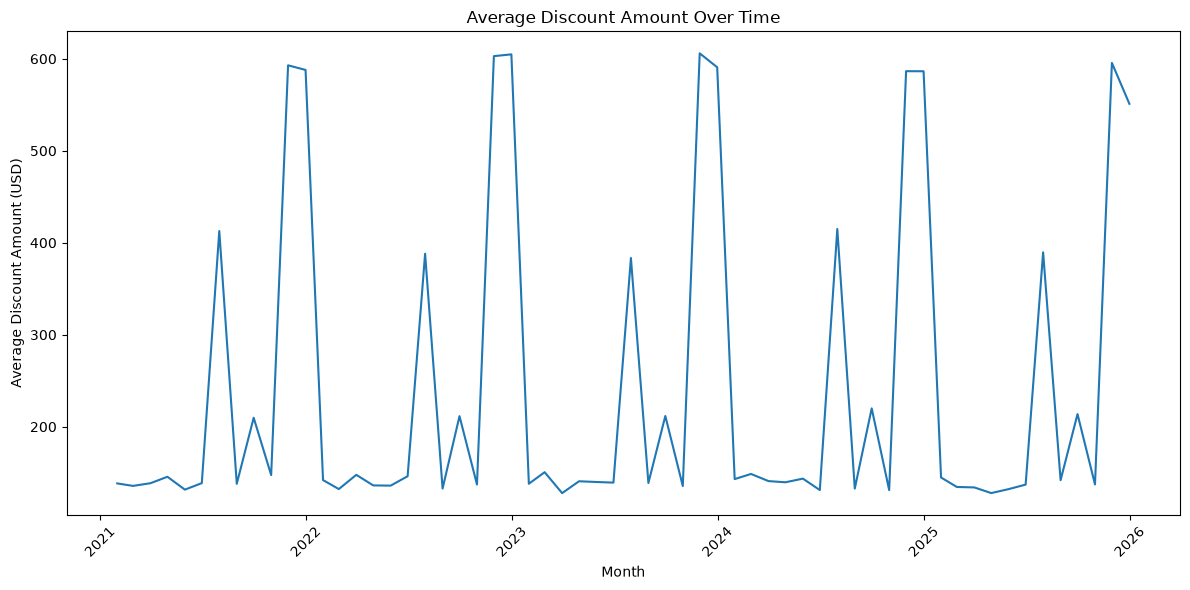

In [64]:
#Average Monthly Discount

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_discount_analysis["order_date"],
    monthly_discount_analysis["average_discount"]
)

plt.title("Average Discount Amount Over Time")
plt.xlabel("Month")
plt.ylabel("Average Discount Amount (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Key Finding — Monthly Discount vs. Profit Margin Findings**

- **Higher average discount amounts were associated with lower profit margins**, particularly during seasonal periods with increased discounting.
- **November and December recorded the highest average discounts**, at $596.80 and $584.33, respectively, alongside the lowest profit margins of 27.30% and 27.36%.
- **July also showed elevated discounting**, averaging $397.78 per order, with a profit margin of 35.93%.
- **Most other calendar months maintained average discounts near $140**, with profit margins generally around 45%.
- **November and December recorded the highest order volumes**, suggesting that increased purchasing activity coincided with heavier discounting and reduced profit margins.

**Key Finding:** Months with higher average discount amounts tended to have lower profit margins, especially during the holiday shopping season. These findings highlight the importance of monitoring both sales volume and profitability when evaluating discount strategies.

*Note: Calendar-month metrics combine completed USD orders from 2021–2025. The observed relationship does not establish that discounts caused lower profit margins.*

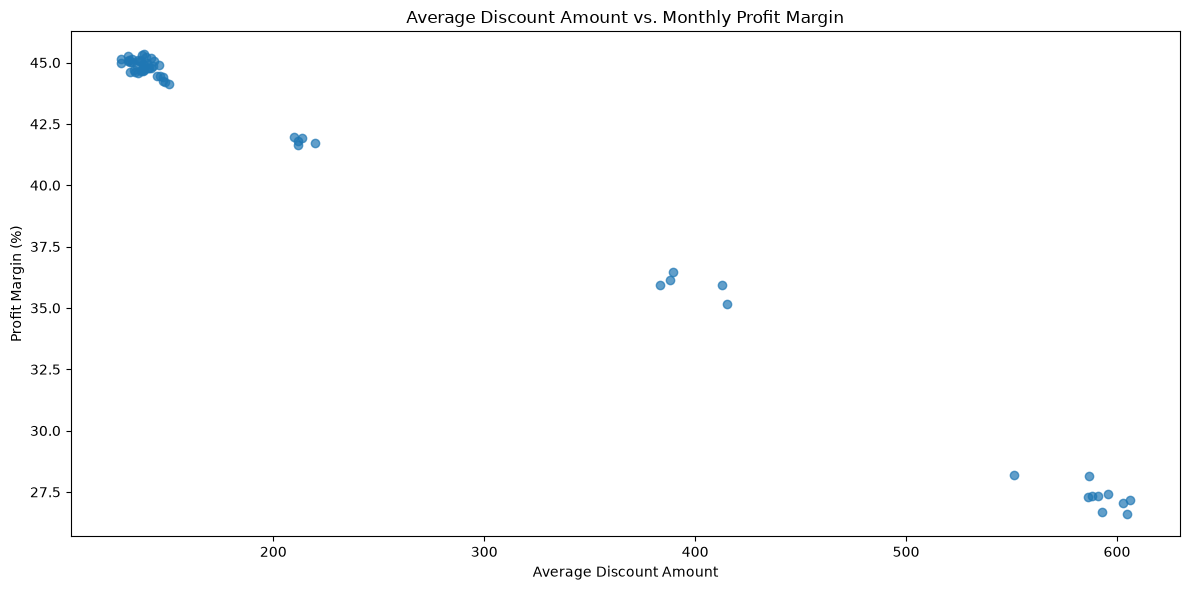

In [65]:
# Monthly Discount vs. Profit Margin
plt.figure(figsize=(12, 6))

plt.scatter(
    monthly_discount_analysis["average_discount"],
    monthly_discount_analysis["profit_margin_percentage"],
    alpha=0.7
)

plt.title("Average Discount Amount vs. Monthly Profit Margin")
plt.xlabel("Average Discount Amount")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

**Key Finding — Discount Amount and Monthly Profit Margin**

The scatter plot shows a clear inverse relationship between average monthly discount amounts and profit margins. Months with average discounts around 110 correspond to profit margins near 47%, while months with average discounts around 490–550 correspond to margins near 33%. Intermediate clusters show a similar pattern, with higher average discounts associated with lower margins.

Together, these results suggest that seasonal discounting may be an important factor to investigate when evaluating profitability. Comparing discount strategies, product mix, and sales performance during high-discount periods could help determine whether these promotions generate sufficient additional sales to justify their lower margins.

In [66]:

# Compare average discount and profit margin by calendar month
# Completed USD orders only

sales_usd["calendar_month"] = sales_usd["order_date"].dt.month

calendar_month_analysis = (
    sales_usd.groupby("calendar_month")
    .agg(
        average_discount=("discount_amount", "mean"),
        net_sales=("net_sales", "sum"),
        profit=("profit", "sum"),
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

calendar_month_analysis["profit_margin_percentage"] = (
    calendar_month_analysis["profit"]
    / calendar_month_analysis["net_sales"]
) * 100

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

calendar_month_analysis["month_name"] = (
    calendar_month_analysis["calendar_month"].map(month_names)
)

display(
    calendar_month_analysis[
        ["month_name", "order_count", "average_discount",
         "profit_margin_percentage"]
    ].round(2)
)


,month_name,order_count,average_discount,profit_margin_percentage
0,January,4809,141.27,44.82
1,February,3904,140.23,44.50
2,March,5320,137.80,44.76
3,April,4979,138.04,44.99
4,May,5034,136.61,44.97
5,June,5304,138.50,44.96
6,July,4995,397.78,35.93
7,August,5993,136.92,45.00
8,September,5348,213.37,41.81
9,October,5761,137.74,44.73


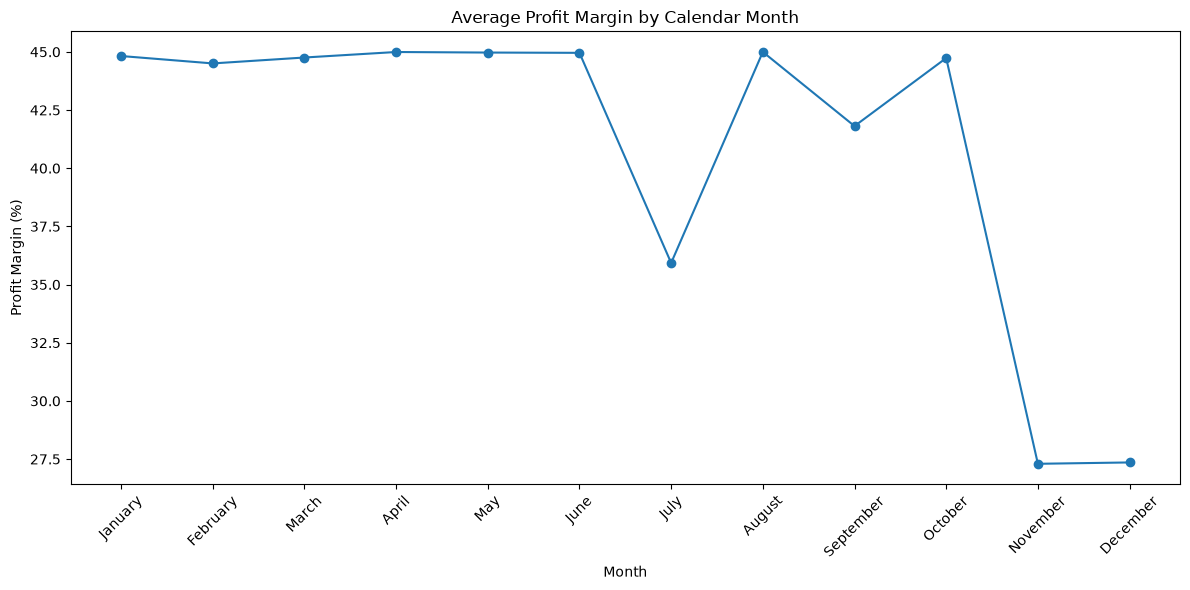

In [67]:
# Average Profit Margin by Calendar Month

plt.figure(figsize=(12, 6))

plt.plot(
    calendar_month_analysis["month_name"],
    calendar_month_analysis["profit_margin_percentage"],
    marker="o"
)

plt.title("Average Profit Margin by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Key Finding — Seasonal Profitability Patterns**

1. November and December have the highest average discounts, at $596.80 and $584.33, respectively.
2. Profit margins are lowest in November (27.30%) and December (27.36%), compared with approximately 45% during most other months.
3. July also stands out, with an average discount of $397.78 and a lower profit margin of 35.93%.
4. November and December have the highest order volumes, at 7,863 and 8,668 orders, respectively.
These patterns suggest that periods with higher discount amounts are associated with lower profit margins and, particularly toward the end of the year, higher order volumes.

However, this analysis alone cannot establish whether discounting caused those changes.

### Discount and Profitability Summary

- **Overall profitability:** Completed USD orders generated $83.34 million in net sales and $32.86 million in profit, resulting in an overall profit margin of 39.43%.
- **Discount distribution:** The average discount was $273.16 per order, compared with a median of $132.94, indicating a right-skewed distribution.
- **Discounts and profit margins:** Orders with discounts of $0.01–$50 had an average profit margin of 49.22%, compared with 33.67% for orders discounted by more than $200.
- **Seasonal discount patterns:** November and December recorded the highest average discounts at $596.80 and $584.33, respectively.
- **Seasonal profitability:** November and December also recorded the lowest profit margins at 27.30% and 27.36%, while most other months maintained margins near 45%.
- **Order volume:** November and December had the highest combined five-year order counts, with 7,863 and 8,668 orders, respectively.

**Key Finding:** Higher discount amounts were associated with lower profit margins, particularly during November and December, when order volumes were also highest.

*Note: All financial metrics reflect completed USD orders from 2021–2025. These relationships are observational and do not establish that discounts caused changes in profitability.*

## Key EDA Findings & Business Recommendations

The exploratory data analysis examined sales performance, product profitability, customer purchasing behavior, and discount patterns from 2021 through 2025. The financial analysis focused on 67,978 completed USD orders, generating $83.34 million in net sales and $32.86 million in profit.

### Key Findings

**1. The business generated $83.34 million in net sales with an overall profit margin of 39.43%.**

Completed USD orders generated $32.86 million in profit. However, profitability varied across product categories, customer segments, and seasonal periods, demonstrating the importance of evaluating profit alongside revenue.

**2. Electronics generated the highest product-category revenue and profit but had the lowest profit margin.**

Electronics generated approximately $19.34 million in net sales and $5.90 million in profit, with a margin of 30.52%. Grocery recorded the highest profit margin at 52.65%, followed by strong profitability in Beauty & Personal Care at 49.71%.

**3. Loyal customers were the primary contributors to revenue.**

Customers classified as Loyal generated 93.94% of total net sales and averaged 5.04 completed USD orders per customer. Although New customers had the highest average order value at $1,327.70, Loyal customers generated greater cumulative spending through more frequent purchases.

**4. Higher discount amounts were associated with lower profit margins.**

Orders discounted by $0.01–$50 had an average profit margin of 49.22%, compared with 33.67% for orders discounted by more than $200. November and December recorded the highest average discounts and lowest calendar-month profit margins, alongside the highest order volumes.

### Business Recommendations

- **Review seasonal discount strategies.** Evaluate whether higher discounts during November and December generate sufficient additional sales and profit to justify lower margins. Compare promotional performance across periods before adjusting discount policies.
- **Investigate Electronics profitability.** Examine product costs, pricing, and discount patterns to identify opportunities to improve margins while maintaining the category's strong revenue contribution.
- **Strengthen customer retention.** Develop strategies that encourage first-time customers to make repeat purchases while maintaining engagement with existing Loyal customers.
- **Explore opportunities in high-margin categories.** Evaluate the growth potential of Grocery and Beauty & Personal Care while considering customer demand, sales volume, and operational costs.
- **Monitor sales and profitability together.** Track net sales, order volume, average order value, total profit, and profit margin to evaluate business performance and identify emerging trends.

### Conclusion

The analysis demonstrates that revenue alone does not provide a complete picture of business performance. Product profitability, customer purchase frequency, and discounting patterns provide additional context for understanding financial results.

By evaluating these factors together, the business can identify opportunities to strengthen customer relationships, improve promotional strategies, and support sustainable profitability.

*Data limitations: Financial metrics reflect completed USD orders from 2021–2025. Customer classifications were supplied by the dataset and do not necessarily represent lifetime customer behavior. Product-category financial metrics are based on item-level transactions, while overall sales and profit figures use order-level records; these totals do not fully reconcile. Observed relationships are descriptive and do not establish causation.*